# LoRA Hyperparameter Analysis
Regression analysis and visualization of dataset size × batch size effects on LoRA fidelity metrics.

In [1]:
!pip install statsmodels matplotlib seaborn pandas numpy tabulate -q

## 1. Load Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np

# Load from CSV in the root of Google Drive
df = pd.read_csv("/content/drive/MyDrive/lora_metrics.csv")
df = df.rename(columns={'fid_vs_refs': 'fid'})

# Convert run_id from "run_01" string to integer
df['run_id'] = df['run_id'].str.replace('run_', '').astype(int)

# Drop columns not used in the analysis
df = df.drop(columns=['num_eval_images', 'max_steps', 'overfit_ratio'], errors='ignore')

# Exploratory composite from an earlier draft (arbitrary 0.25 weight); not used in any reported result
df['identity_dominance'] = df['clip_identity'] - 0.25 * df['diversity_lpips']

# Create log-transformed columns
df['log_data']   = np.log2(df['data_size'])
df['log_batch']  = np.log2(df['batch_size'])
df['log_epochs'] = np.log2(df['epochs'])

print(df.to_string(index=False))
print(f"\nShape: {df.shape}")

 run_id  data_size  batch_size  epochs  clip_identity  lpips_identity        fid  diversity_lpips  identity_dominance  log_data  log_batch  log_epochs
      1        400           4      25       0.847405        0.526701 191.668517         0.546048            0.710893  8.643856        2.0    4.643856
      2        400           2      25       0.843261        0.523061 207.697964         0.528593            0.711113  8.643856        1.0    4.643856
      3        400           1      25       0.852696        0.523678 198.259703         0.547685            0.715775  8.643856        0.0    4.643856
      4        200           4      50       0.865243        0.508646 193.525229         0.496636            0.741084  7.643856        2.0    5.643856
      5        200           2      50       0.857724        0.508229 200.961178         0.520108            0.727697  7.643856        1.0    5.643856
      6        200           1      50       0.855486        0.508698 191.874799         0.523

## 2. Model A — Practitioner Variables (data size × batch size)

In [4]:
import statsmodels.formula.api as smf

metrics = ['clip_identity', 'lpips_identity', 'fid', 'diversity_lpips']

print("=" * 70)
print("MODEL A: metric ~ log_data * log_batch (what practitioners control)")
print("=" * 70)

results_a = {}
for m in metrics:
    formula = f'{m} ~ log_data * log_batch'
    model = smf.ols(formula, data=df).fit()
    results_a[m] = model
    print(f"\n--- {m} ---")
    print(model.summary2().tables[1].to_string())
    print(f"  R² = {model.rsquared:.4f},  Adj R² = {model.rsquared_adj:.4f}")

MODEL A: metric ~ log_data * log_batch (what practitioners control)

--- clip_identity ---
                       Coef.  Std.Err.          t         P>|t|    [0.025    0.975]
Intercept           0.903274  0.013774  65.577080  1.285704e-15  0.872957  0.933591
log_data           -0.006373  0.002028  -3.142752  9.362359e-03 -0.010836 -0.001910
log_batch          -0.000199  0.010669  -0.018647  9.854569e-01 -0.023682  0.023284
log_data:log_batch  0.000021  0.001571   0.013497  9.894730e-01 -0.003436  0.003478
  R² = 0.6904,  Adj R² = 0.6060

--- lpips_identity ---
                       Coef.  Std.Err.          t         P>|t|    [0.025    0.975]
Intercept           0.515569  0.019356  26.636824  2.425583e-11  0.472968  0.558171
log_data            0.000299  0.002849   0.104944  9.183094e-01 -0.005973  0.006571
log_batch           0.007985  0.014993   0.532573  6.049201e-01 -0.025014  0.040983
log_data:log_batch -0.000946  0.002207  -0.428556  6.765179e-01 -0.005804  0.003912
  R² = 0.0525

## 3. Model B — Epoch Confound Test

In [5]:
print("=" * 70)
print("MODEL B: metric ~ log_epochs (is overfitting the real driver?)")
print("=" * 70)

results_b = {}
for m in metrics:
    formula = f'{m} ~ log_epochs'
    model = smf.ols(formula, data=df).fit()
    results_b[m] = model
    print(f"\n--- {m} ---")
    print(model.summary2().tables[1].to_string())
    print(f"  R² = {model.rsquared:.4f},  Adj R² = {model.rsquared_adj:.4f}")

# Side-by-side comparison
print("\n" + "=" * 70)
print("COMPARISON: Model A (data × batch) vs Model B (epochs alone)")
print("=" * 70)
print(f"{'Metric':<20} {'A: R²_adj':>10} {'B: R²_adj':>10} {'Winner':>10}")
print("-" * 55)
for m in metrics:
    a_adj = results_a[m].rsquared_adj
    b_adj = results_b[m].rsquared_adj
    winner = "Epochs" if b_adj >= a_adj else "Data×Batch"
    print(f"{m:<20} {a_adj:>10.4f} {b_adj:>10.4f} {winner:>10}")

MODEL B: metric ~ log_epochs (is overfitting the real driver?)

--- clip_identity ---
               Coef.  Std.Err.           t         P>|t|    [0.025    0.975]
Intercept   0.818676  0.008014  102.158103  2.840730e-20  0.801363  0.835989
log_epochs  0.006352  0.001180    5.383829  1.245456e-04  0.003803  0.008900
  R² = 0.6904,  Adj R² = 0.6666

--- lpips_identity ---
               Coef.  Std.Err.          t         P>|t|    [0.025    0.975]
Intercept   0.514959  0.011504  44.764249  1.253463e-15  0.490106  0.539811
log_epochs  0.000647  0.001694   0.381959  7.086629e-01 -0.003012  0.004306
  R² = 0.0111,  Adj R² = -0.0650

--- fid ---
                 Coef.  Std.Err.          t         P>|t|      [0.025      0.975]
Intercept   206.083975   8.94579  23.036978  6.338069e-12  186.757770  225.410180
log_epochs   -1.337755   1.31697  -1.015782  3.282664e-01   -4.182896    1.507387
  R² = 0.0735,  Adj R² = 0.0023

--- diversity_lpips ---
               Coef.  Std.Err.          t         

## 4. Partial Effects Plots

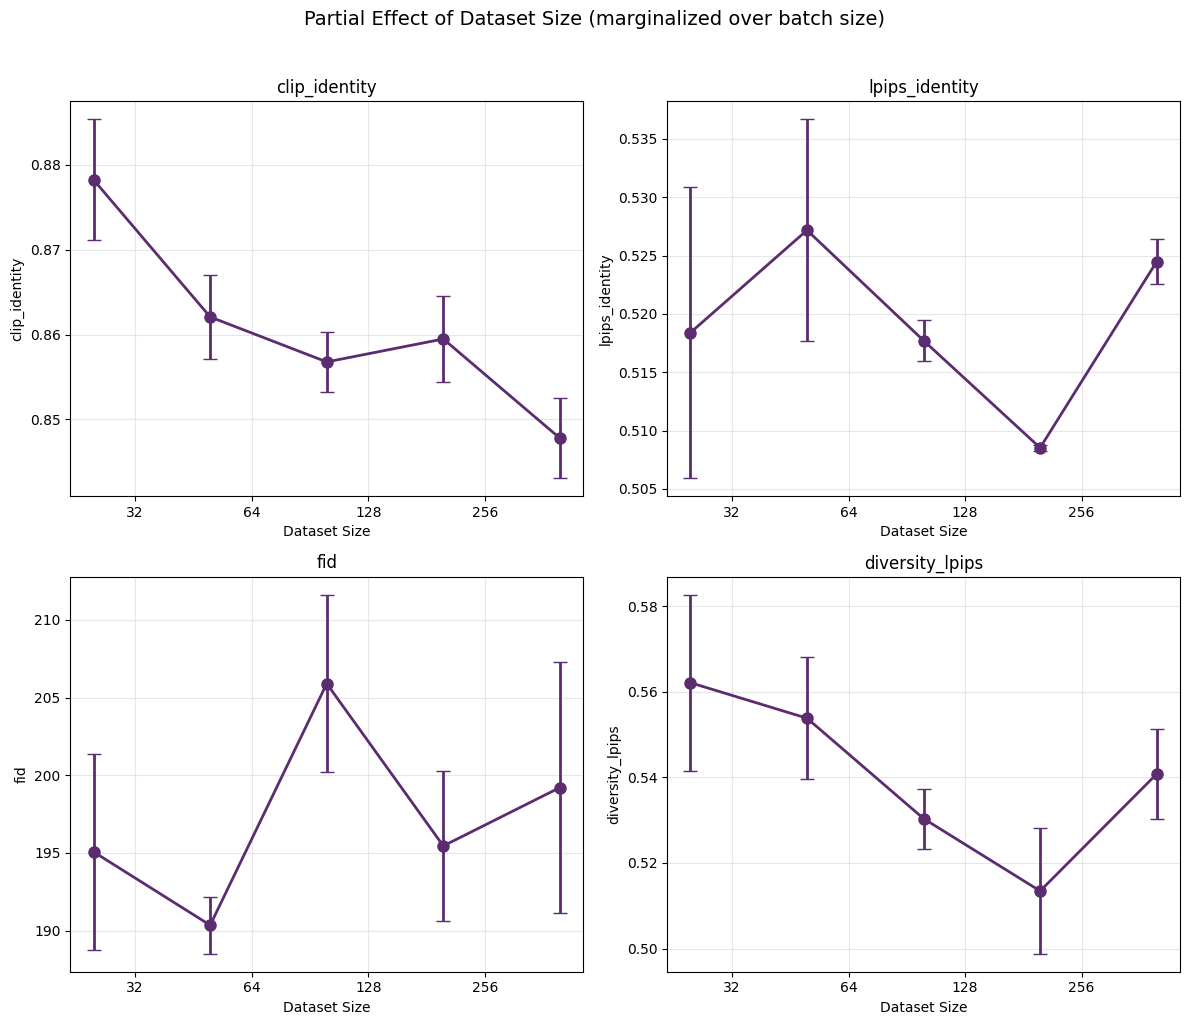

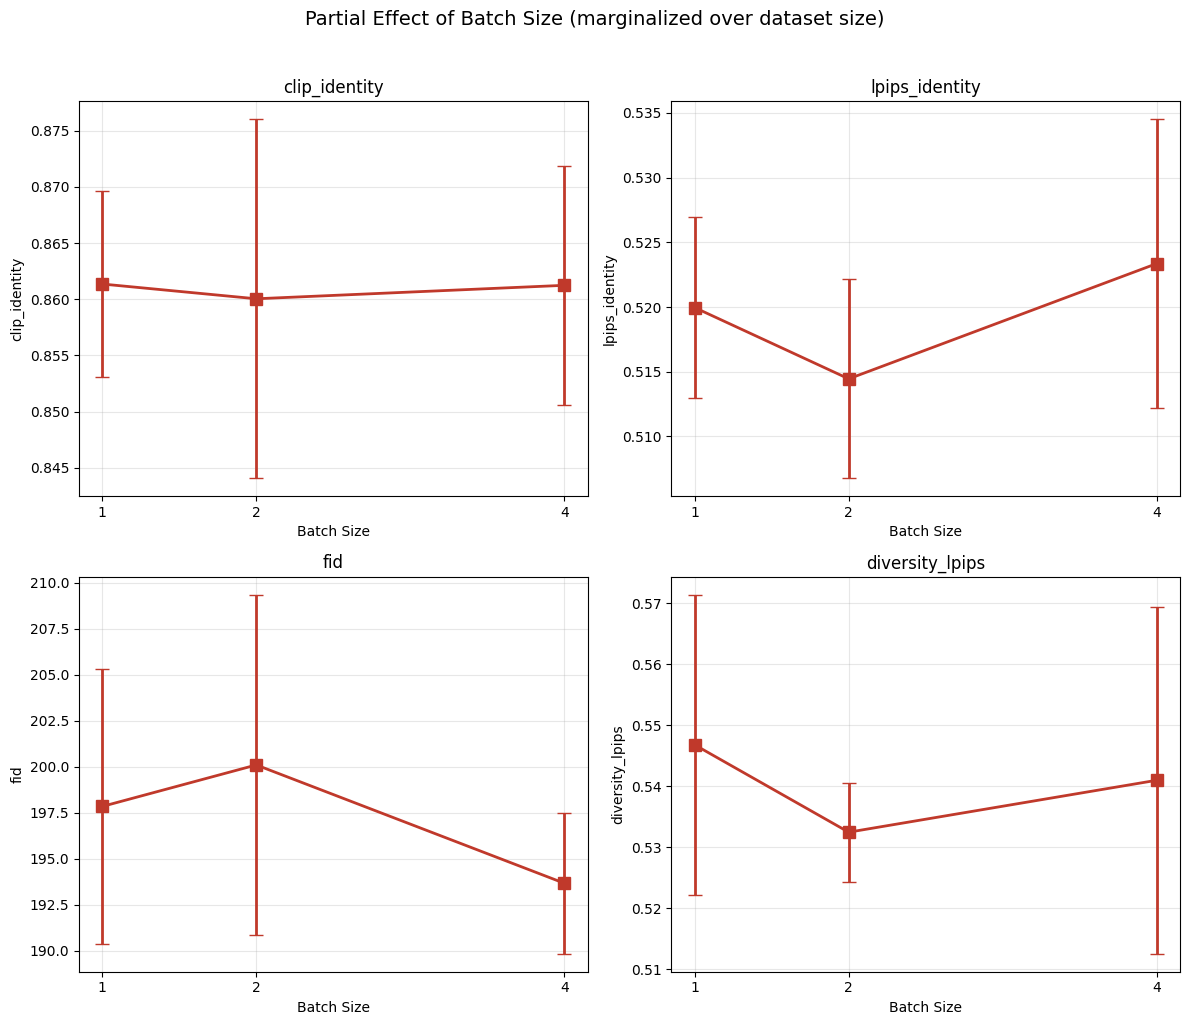

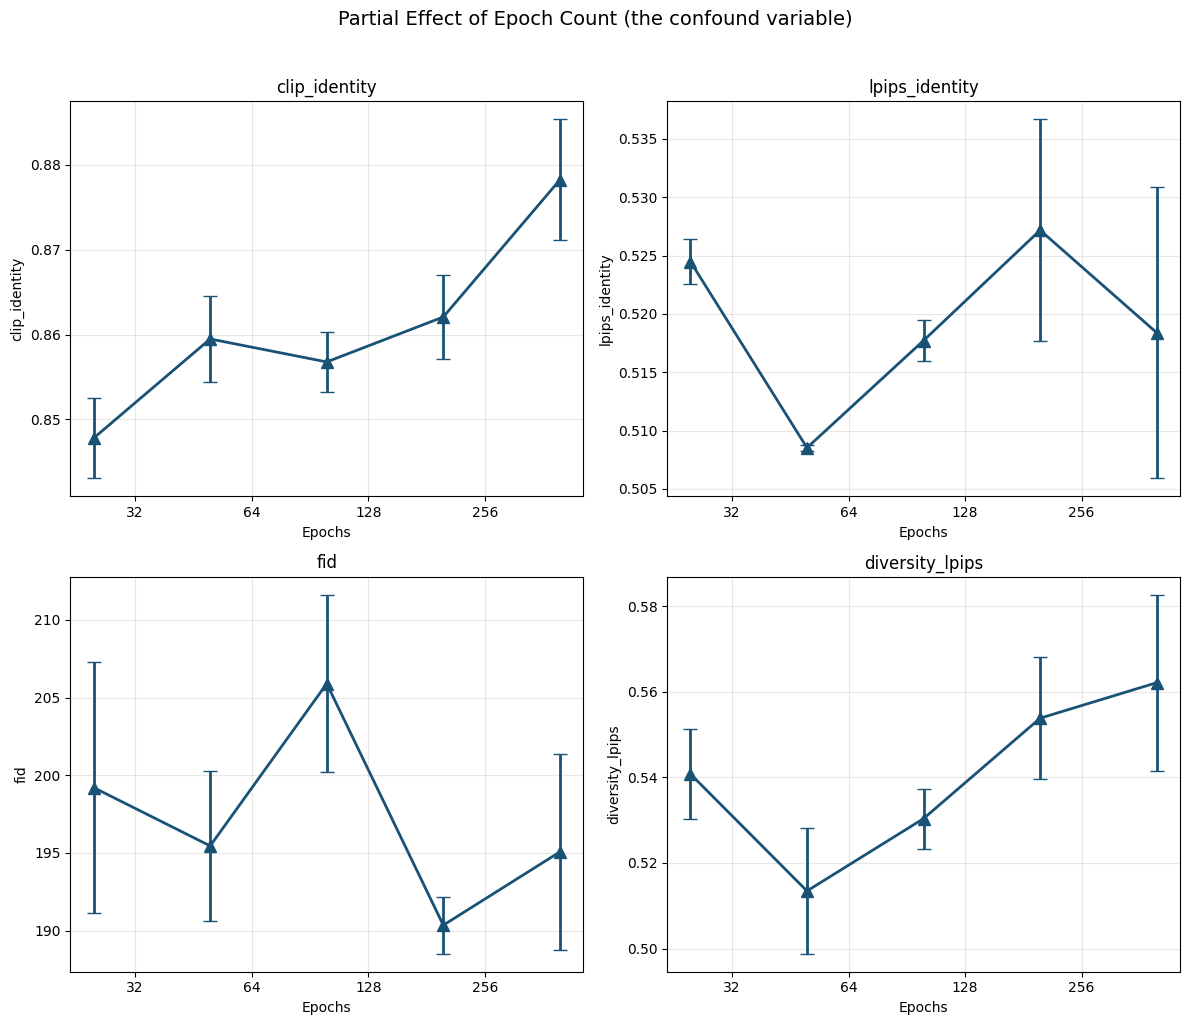

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plot_metrics = ['clip_identity', 'lpips_identity', 'fid', 'diversity_lpips']

# --- Plot 1: Partial effect of DATA SIZE (averaging over batch sizes) ---
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Partial Effect of Dataset Size (marginalized over batch size)', fontsize=14, y=1.02)

for idx, metric in enumerate(plot_metrics):
    ax = axes.flat[idx]
    grouped = df.groupby('data_size')[metric].agg(['mean', 'std']).reset_index()
    ax.errorbar(grouped['data_size'], grouped['mean'], yerr=grouped['std'],
                marker='o', capsize=5, linewidth=2, markersize=8, color='#5B2C6F')
    ax.set_xlabel('Dataset Size')
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.set_xscale('log', base=2)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('partial_effect_data_size.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Plot 2: Partial effect of BATCH SIZE (averaging over data sizes) ---
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Partial Effect of Batch Size (marginalized over dataset size)', fontsize=14, y=1.02)

for idx, metric in enumerate(plot_metrics):
    ax = axes.flat[idx]
    grouped = df.groupby('batch_size')[metric].agg(['mean', 'std']).reset_index()
    ax.errorbar(grouped['batch_size'], grouped['mean'], yerr=grouped['std'],
                marker='s', capsize=5, linewidth=2, markersize=8, color='#C0392B')
    ax.set_xlabel('Batch Size')
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.set_xticks([1, 2, 4])
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('partial_effect_batch_size.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Plot 3: Partial effect of EPOCHS (the confound) ---
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Partial Effect of Epoch Count (the confound variable)', fontsize=14, y=1.02)

for idx, metric in enumerate(plot_metrics):
    ax = axes.flat[idx]
    grouped = df.groupby('epochs')[metric].agg(['mean', 'std']).reset_index()
    ax.errorbar(grouped['epochs'], grouped['mean'], yerr=grouped['std'],
                marker='^', capsize=5, linewidth=2, markersize=8, color='#1A5276')
    ax.set_xlabel('Epochs')
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.set_xscale('log', base=2)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('partial_effect_epochs.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Heatmaps (Dataset Size × Batch Size)

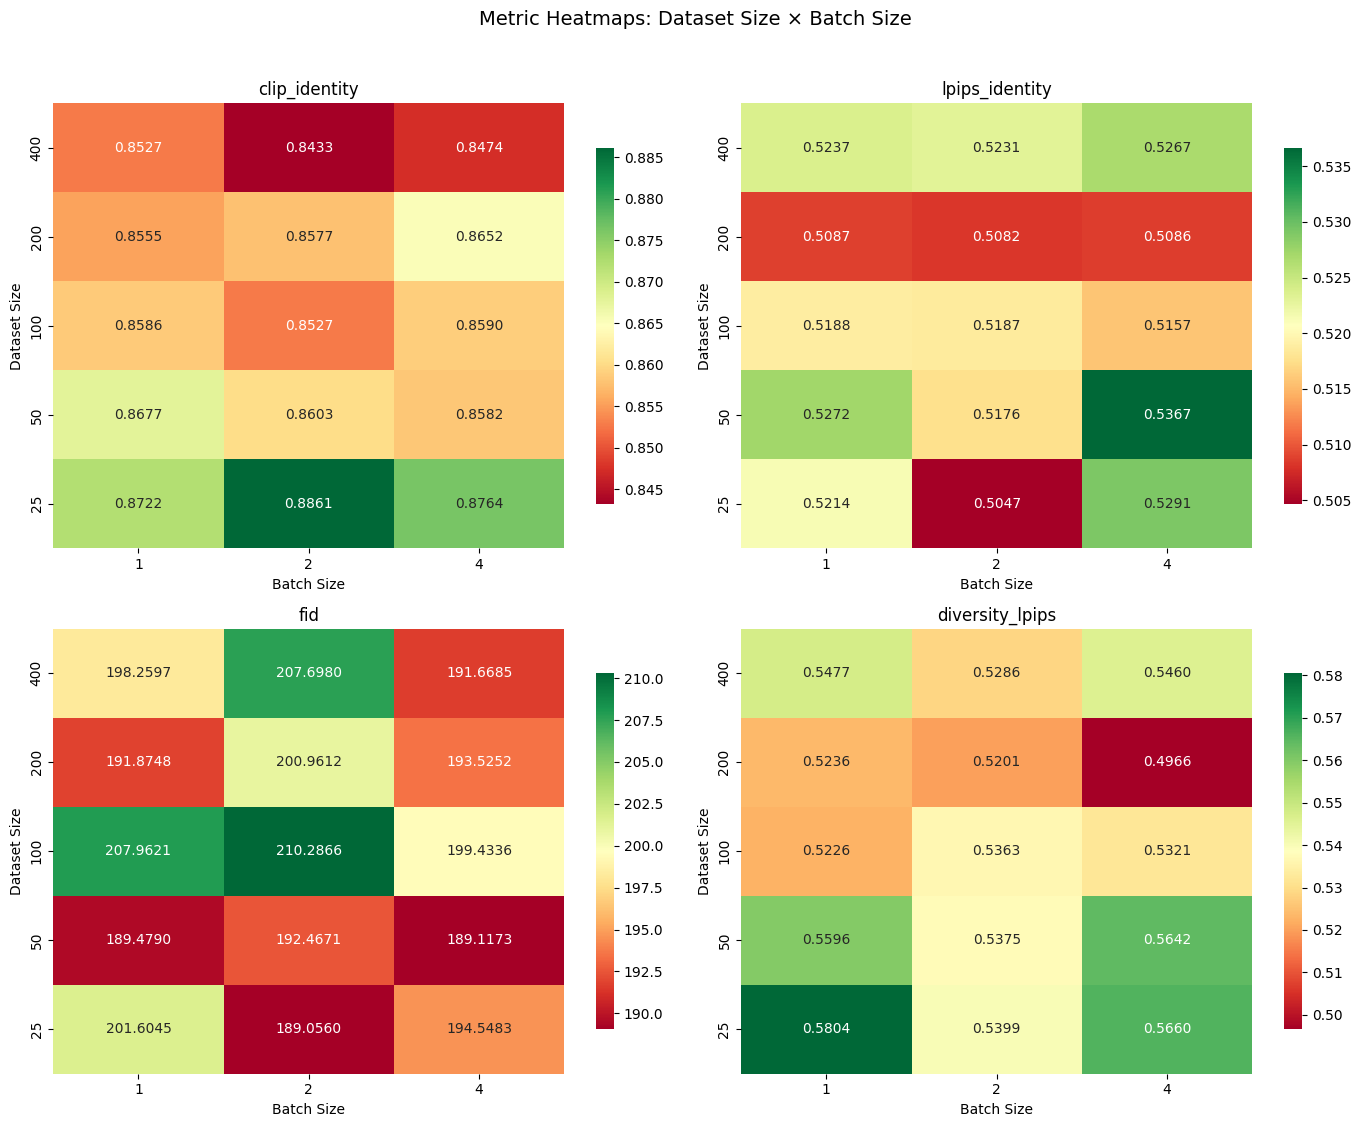

In [7]:
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle('Metric Heatmaps: Dataset Size × Batch Size', fontsize=14, y=1.02)

for idx, metric in enumerate(plot_metrics):
    ax = axes.flat[idx]
    pivot = df.pivot_table(index='data_size', columns='batch_size', values=metric)
    sns.heatmap(pivot, annot=True, fmt='.4f', cmap='RdYlGn', ax=ax,
                cbar_kws={'shrink': 0.8})
    ax.set_title(metric)
    ax.set_ylabel('Dataset Size')
    ax.set_xlabel('Batch Size')
    ax.invert_yaxis()

plt.tight_layout()
plt.savefig('metric_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. CLIP Identity vs Diversity over Epochs

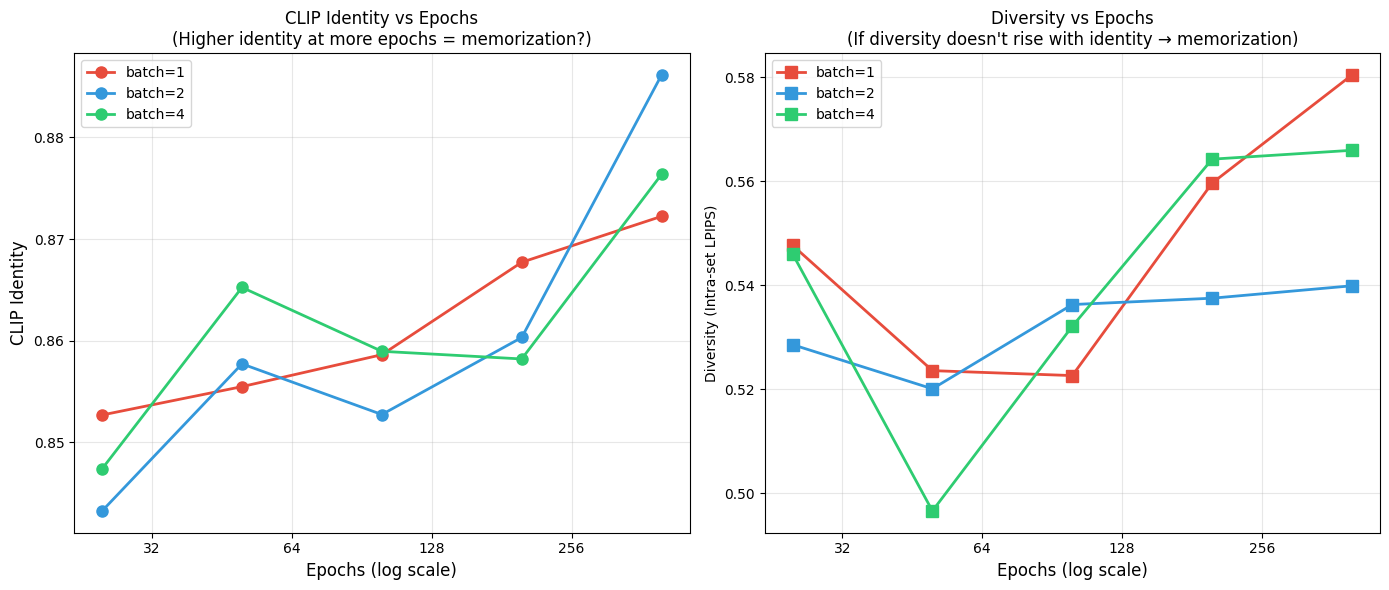

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = {1: '#E74C3C', 2: '#3498DB', 4: '#2ECC71'}

# Left: CLIP identity vs epochs, colored by batch size
ax = axes[0]
for bs in [1, 2, 4]:
    subset = df[df['batch_size'] == bs].sort_values('epochs')
    ax.plot(subset['epochs'], subset['clip_identity'],
            marker='o', label=f'batch={bs}', color=colors[bs],
            linewidth=2, markersize=8)
ax.set_xlabel('Epochs (log scale)', fontsize=12)
ax.set_ylabel('CLIP Identity', fontsize=12)
ax.set_title('CLIP Identity vs Epochs\n(Higher identity at more epochs = memorization?)', fontsize=12)
ax.set_xscale('log', base=2)
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.legend()
ax.grid(True, alpha=0.3)

# Right: Diversity vs epochs, colored by batch size
ax = axes[1]
for bs in [1, 2, 4]:
    subset = df[df['batch_size'] == bs].sort_values('epochs')
    ax.plot(subset['epochs'], subset['diversity_lpips'],
            marker='s', label=f'batch={bs}', color=colors[bs],
            linewidth=2, markersize=8)
ax.set_xlabel('Epochs (log scale)', fontsize=12)
ax.set_ylabel('Diversity (Intra-set LPIPS)')
ax.set_title('Diversity vs Epochs\n(If diversity doesn\'t rise with identity → memorization)', fontsize=12)
ax.set_xscale('log', base=2)
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('memorization_evidence.png', dpi=150, bbox_inches='tight')
plt.show()

**Note on interpretation.** The plot titles above (and the printout in Section 7) state the memorization check as originally planned: memorization would show up as CLIP identity rising while diversity does not. Diversity in fact rose with epochs (r = +0.57), so this check does not indicate memorization. Diversity measured as intra-set LPIPS can also rise because of artifacts, so it doesn't rule memorization out either. The titles are left as originally run so the code matches the saved figures. See the README for the current interpretation.

## 7. Summary Table and Key Findings

In [9]:
# Clean summary table you can paste directly into your document
summary = df[['run_id', 'data_size', 'batch_size', 'epochs',
              'clip_identity', 'lpips_identity', 'diversity_lpips', 'fid']].copy()

summary = summary.sort_values(['data_size', 'batch_size'], ascending=[False, False])

print("\nFormatted results table:")
print(summary.to_markdown(index=False, floatfmt='.4f'))

# Key finding summary
print("\n\nKEY FINDINGS:")
print("-" * 50)
corr_epochs_clip = df['log_epochs'].corr(df['clip_identity'])
corr_batch_clip  = df['log_batch'].corr(df['clip_identity'])
corr_data_clip   = df['log_data'].corr(df['clip_identity'])
print(f"Correlation of log(epochs)     with CLIP identity: {corr_epochs_clip:+.4f}")
print(f"Correlation of log(data_size)  with CLIP identity: {corr_data_clip:+.4f}")
print(f"Correlation of log(batch_size) with CLIP identity: {corr_batch_clip:+.4f}")

corr_epochs_div = df['log_epochs'].corr(df['diversity_lpips'])
print(f"\nCorrelation of log(epochs) with diversity: {corr_epochs_div:+.4f}")
print("(If CLIP identity rises with epochs but diversity doesn't → memorization)")


Formatted results table:
|   run_id |   data_size |   batch_size |   epochs |   clip_identity |   lpips_identity |   diversity_lpips |      fid |
|---------:|------------:|-------------:|---------:|----------------:|-----------------:|------------------:|---------:|
|   1.0000 |    400.0000 |       4.0000 |  25.0000 |          0.8474 |           0.5267 |            0.5460 | 191.6685 |
|   2.0000 |    400.0000 |       2.0000 |  25.0000 |          0.8433 |           0.5231 |            0.5286 | 207.6980 |
|   3.0000 |    400.0000 |       1.0000 |  25.0000 |          0.8527 |           0.5237 |            0.5477 | 198.2597 |
|   4.0000 |    200.0000 |       4.0000 |  50.0000 |          0.8652 |           0.5086 |            0.4966 | 193.5252 |
|   5.0000 |    200.0000 |       2.0000 |  50.0000 |          0.8577 |           0.5082 |            0.5201 | 200.9612 |
|   6.0000 |    200.0000 |       1.0000 |  50.0000 |          0.8555 |           0.5087 |            0.5236 | 191.8748 |
|   7.